# ASMSA v2 &mdash; Prepare

&#8592; [Setup](01-setup.ipynb) &nbsp;|&nbsp; [Tune](03-tune.ipynb) &#8594;

| | |
|---|---|
| **What it does** | Build the GROMACS topology, split the trajectory honestly, featurize into internal coordinates, and standardize. |
| **Typical runtime** | a few minutes; featurization dominates |
| **Needs** | a saved project from <a href='01-setup.ipynb'>01-setup</a> |
| **Produces** | <code>features.pt</code>, <code>scaler.npz</code>, <code>split.npz</code>, <code>features-model.pt</code> |

---

In [1]:
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import mdtraj as md

import asmsa_v2 as asmsa
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
project = asmsa.Project.load('run')
asmsa.set_seed(0)
project

root,/home/tedeschg/prj/ASMSA_v2/notebooks/run
conf,/home/tedeschg/prj/unfolding-data/trpcage_npt400_nH.pdb
traj,/home/tedeschg/prj/unfolding-data/trpcage_ds_nH.xtc
components,(single molecule)
model,norm / prior=uniform / latent_dim=2
split,"random (0.7, 0.15, 0.15)"
md,100.0 ns @ 300.0 K
✓,01 prepare (features)
✓,01 prepare (scaler)
✓,01 prepare (split)
✓,02 tune


## 1. GROMACS topology *(optional here, required for 06-md)*

`gmx pdb2gmx` turns the hydrogen-free PDB into a topology, a `.gro` **with** hydrogens,
and an index file. Three things come out of it that the rest of the pipeline depends on
being mutually consistent, so generating them together is the point.

If GROMACS is not installed this cell reports the command it *would* run and the rest of
the notebook proceeds normally &mdash; the topology is not needed until
[05-plumed](05-plumed.ipynb) and [06-md](06-md.ipynb).

In [2]:
import os

os.environ["PATH"] = os.pathsep.join([
    "/software/gromacs-2026.3-plumed/bin",
    "/software/plumed/master/bin",
    os.environ["PATH"],
])

from asmsa_v2.md import Gromacs, check_environment

env = check_environment(gmx="gmx", plumed="plumed")
print(env)

HAVE_GMX = "NOT FOUND" not in env["gmx"]
gmx = Gromacs(project.root, gmx="gmx", dry_run=not HAVE_GMX)

{'gmx': '2026.3', 'plumed': '2.11', 'plumed executable': '/software/plumed/master/bin/plumed', 'plumed pytorch module': 'NOT REGISTERED in the selected PLUMED executable; the GROMACS-linked PLUMED may differ'}


In [3]:
from asmsa_v2.md import Gromacs, check_environment

env = check_environment(gmx='gmx')
for tool, version in env.items():
    print(f'  {tool:<22} {version}')

HAVE_GMX = 'NOT FOUND' not in env['gmx']
gmx = Gromacs(project.root, gmx='gmx', dry_run=not HAVE_GMX)

  gmx                    2026.3
  plumed                 2.11
  plumed pytorch module  NOT ENABLED - PYTORCH_MODEL_CV will be unavailable


In [3]:
topol = project.root / project.topol

if topol.exists():
    print(f'[skip] {topol.name} already exists; delete it to rebuild')
else:
    gmx.pdb2gmx(
        f=str(project.conf_path), o=project.gro, p=project.topol,
        n=project.index, water='tip3p', ff='amber99sb-ildn', ignh=True,
    )

if not HAVE_GMX:
    print('\nGROMACS is not installed, so nothing ran. The demo system ships a mock',
          'topology.gro you can use for 05-plumed; a real run needs real GROMACS.')

$ gmx pdb2gmx -f /home/tedeschg/prj/unfolding-data/trpcage_npt400_nH.pdb -o trpcage.gro -p trpcage.top -n trpcage.ndx -water tip3p -ff amber99sb-ildn -ignh   [log: gmx-pdb2gmx-1793438504.log]


## 2. Load and align the trajectory

Features are internal coordinates, so they are invariant to rigid-body motion and
superposition is not strictly required. It is done anyway because every *visual* and
RMSD-based check below is meaningless without it.

In [5]:
traj = md.load(str(project.traj_path), top=str(project.conf_path))
align = traj.top.select('name CA')
if len(align) < 3:
    align = traj.top.select('element != H')
traj.superpose(traj, frame=0, atom_indices=align)

components = {k: traj.top.select(v) for k, v in (project.components or {}).items()}
print(f'{traj.n_frames} frames, {traj.n_atoms} atoms')
for k, v in components.items():
    print(f'  {k:<10} {len(v):>5} atoms')

50001 frames, 144 atoms


## 3. Split train / validation / test

Consecutive MD frames are almost the same structure. Split them at random and a
validation frame sits femtoseconds away from a training frame, so the validation loss
reports memorization and tells you nothing about generalization. `chronological`
confines that leakage to the two block boundaries.

`rmsd_decorrelate_nm` additionally drops training frames within an RMSD cutoff of any
held-out frame &mdash; v1's dataset-bias filter, here on mdtraj instead of parsing
`gmx rms` XPM matrices. It is **O(n_train x n_held)** RMSD evaluations, so it is off by
default; set it in [01-setup](01-setup.ipynb) if you want it.

In [6]:
split = asmsa.split_frames(
    traj.n_frames,
    *project.split_fractions,
    strategy=project.split_strategy,
    seed=0,
)

if project.rmsd_decorrelate_nm:
    print(f'filtering train frames within {project.rmsd_decorrelate_nm} nm '
          f'of any held-out frame (this takes a while)...')
    before = split.train.size
    split = asmsa.decorrelate_by_rmsd(split, traj,
                                      cutoff_nm=project.rmsd_decorrelate_nm,
                                      atom_indices=align)
    print(f'  dropped {before - split.train.size} of {before} train frames')

split

split,frames,share
train,35001,70.0%
val,7500,15.0%
test,7500,15.0%


**What to look for:** a training split of at least a few thousand frames, and a
validation split comfortably larger than your batch size. If `decorrelate_by_rmsd`
removed most of the training set, your trajectory is barely exploring &mdash; the
model will have little to learn from and no amount of tuning will fix that.

## 4. Featurize

Two families of feature, and for a complex you need both:

- **intra-component** &mdash; bonds, angles and dihedrals describing each component's own
  geometry (how the protein is folded, how the ligand is puckered);
- **inter-component** &mdash; distances across the interface. *These* carry the binding
  pose. Without them the latent space cannot distinguish where the ligand sits.

`inter_strategy` controls which atoms contribute inter-component distances:

| Strategy | Pairs | When |
|---|---|---|
| `ca_heavy` | protein C&alpha; &times; ligand heavy atoms | Good default. One atom per residue keeps the count manageable while retaining all ligand motion. |
| `contact` | only atoms that actually touch | Large proteins, where most C&alpha; atoms are nowhere near the binding site. |
| `all` | every cross-component pair | Tiny systems only &mdash; quadratic in atom count. |

In [7]:
n_atoms = traj.n_atoms

if components and len(components) >= 2:
    molecule = asmsa.auto_features(
        traj,
        components=components,
        inter_strategy=project.inter_strategy,
        extract_dihedrals=project.use_dihedrals,
        pdb_for_dihedrals=str(project.conf_path) if project.use_dihedrals else None,
    )
    print(f'ComplexMolecule: {len(components)} components, '
          f"inter_strategy={project.inter_strategy!r}")
else:
    # Single molecule: internal coordinates plus sparse non-bonded distances,
    # which is what v1 did for trp-cage.
    diheds = (asmsa.extract_dihedral_indices_local(str(project.conf_path))
              if project.use_dihedrals else None)
    molecule = asmsa.Molecule(
        pdb=str(project.conf_path), n_atoms=n_atoms, diheds=diheds,
        fms=[asmsa.NBDistancesSparse(n_atoms, density=project.nb_density)],
    )
    print(f'Molecule: single component, nb_density={project.nb_density}')

mol_model = molecule.get_model()

Molecule: single component, nb_density=2


In [8]:
X = asmsa.featurize_frames(traj.xyz, mol_model, chunk_size=2048, progress=True)
print(f'feature tensor: {tuple(X.shape)}  '
      f'({X.element_size() * X.nelement() / 1e6:.1f} MB)')

blocks = dict(mol_model.get_indices())
n_known = max((b for _, b in blocks.values()), default=0)
if n_known < X.shape[1]:
    blocks['inter/nonbonded'] = (n_known, X.shape[1])
for name, (a, b) in blocks.items():
    print(f'  {name:<18} features {a:>5} .. {b:<5} ({b - a} features)')

featurize:   0%|          | 0/25 [00:00<?, ?chunk/s]

feature tensor: (50001, 596)  (119.2 MB)
  dihed4             features     0 .. 85    (85 features)
  inter/nonbonded    features    85 .. 596   (511 features)


### The feature-scale problem

This is the diagnostic that justifies the next cell.

**What to look for:** a max/min standard-deviation ratio in the tens or hundreds, and a
variance share chart in which one block holds essentially all of it. The blocks holding
~0% are the ones an unweighted mean-squared-error reconstruction loss would completely
ignore &mdash; typically the stiff covalent geometry.

> *Note on v1 and early v2:* v1 standardized features before training and folded the same
> transform into the model handed to PLUMED. The initial v2 rewrite dropped that step, so
> on a realistic complex the reconstruction loss was dominated ~100% by the widest block.

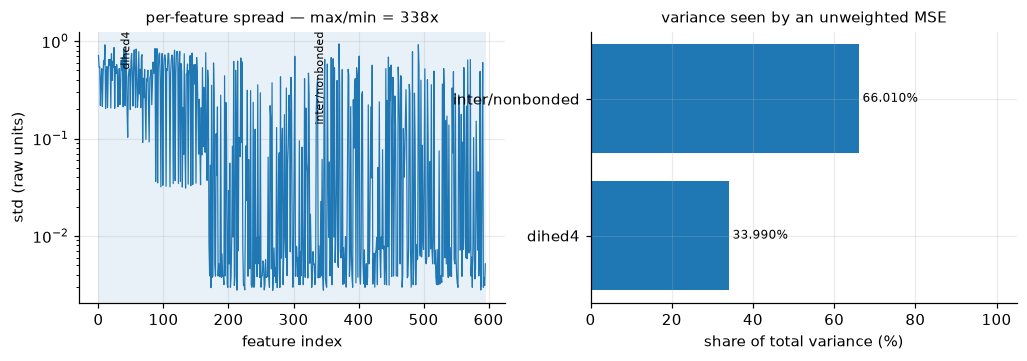

In [9]:
asmsa.viz.feature_scale_report(X.numpy(), blocks=blocks)
plt.show()

## 5. Standardize &mdash; fit on the training split only

Fitting the scaler on all frames would leak validation and test statistics into the
transform. Fit on `split.train`, then apply that same transform everywhere, and save it:
[05-plumed](05-plumed.ipynb) embeds this exact transform inside the model PLUMED loads,
because PLUMED only ever passes raw coordinates and has no idea the features were scaled.

In [10]:
scaler = asmsa.FeatureScaler(method=project.scaler_method).fit(X[split.train])
Xs = scaler.transform(X)

print(scaler.report(X.numpy(), feature_blocks=blocks))
print()
print('after standardization: per-feature std '
      f'{Xs.std(0).min():.4f} .. {Xs.std(0).max():.4f}  (want ~1.0 across the board)')

FeatureScaler(method='standard', n_features=596)
  constant features clamped to scale=1: 0
  raw per-feature std: min=0.0027672 max=0.93624 (ratio 338x)
  raw variance share by block:
    dihed4            33.990%   (std 0.45324 avg over 85 features)
    inter/nonbonded   66.010%   (std 0.16135 avg over 511 features)

after standardization: per-feature std 0.9915 .. 1.0075  (want ~1.0 across the board)


## 6. Save

Everything later stages need, under the canonical names `Project` defines, so no two
notebooks can disagree about where an artifact lives.

In [11]:
torch.save({'features': Xs, 'features_raw': X,
            'feature_blocks': blocks,
            'n_atoms': n_atoms,
            'components': {k: np.asarray(v) for k, v in components.items()}},
           project.features_file)
scaler.save(project.scaler_file)
np.savez(project.split_file, train=split.train, val=split.val, test=split.test,
         strategy=np.array(split.strategy))

from asmsa_v2.export import export_features_model
features_model_path = export_features_model(
    mol_model, n_atoms, project.dir('models') / 'features-model.pt')

for p in (project.features_file, project.scaler_file, project.split_file,
          features_model_path):
    print(f'  {p.relative_to(project.root)}  '
          f'({p.stat().st_size / 1e6:.2f} MB)')

/home/tedeschg/prj/ASMSA_v2/.venv/lib/python3.12/site-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/tedeschg/prj/ASMSA_v2/.venv/lib/python3.12/site-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:324: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert input.shape[0] == self.n_atoms
/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:325: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python valu

  01-datasets/features.pt  (238.41 MB)
  01-datasets/scaler.npz  (0.01 MB)
  01-datasets/split.npz  (0.40 MB)
  03-models/features-model.pt  (0.03 MB)


### Verify the saved featurizer

The TorchScript featurizer saved above is the one that will run inside PLUMED during the
simulation. If it disagrees with the Python featurization used for training, the
simulation biases a different quantity than you analysed &mdash; silently. Check now.

In [12]:
loaded = torch.jit.load(str(features_model_path))
loaded.eval()
with torch.no_grad():
    check = loaded(torch.as_tensor(np.transpose(traj.xyz[:64], (1, 2, 0)),
                                   dtype=torch.float32)).T
err = float((check - X[:64]).abs().max())
print(f'TorchScript featurizer vs Python: max |diff| = {err:.3e}')
assert err < 1e-4, 'the saved featurizer does not reproduce the training features'
print('OK')

TorchScript featurizer vs Python: max |diff| = 0.000e+00
OK


/home/tedeschg/prj/ASMSA_v2/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## Optional: a quick look at the raw data

Interpretable observables per frame. Colouring the latent space by these in
[04-train](04-train.ipynb) is how you find out *what the model learned* &mdash; so it
helps to know their range first.

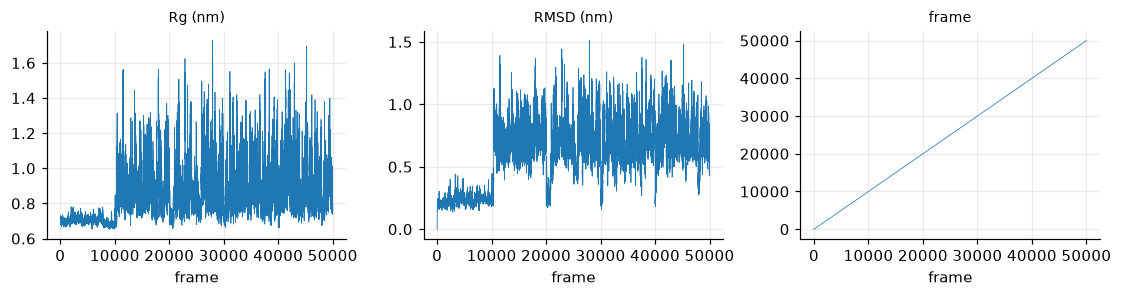

In [13]:
props = asmsa.viz.standard_properties(traj, components or None)

fig, axes = plt.subplots(1, len(props), figsize=(3.4 * len(props), 2.8))
for ax, (name, vals) in zip(np.atleast_1d(axes), props.items()):
    ax.plot(vals, lw=0.5)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('frame')
plt.tight_layout(); plt.show()

np.savez(project.dir('datasets') / 'properties.npz', **props)

---

&#8592; [Setup](01-setup.ipynb) &nbsp;|&nbsp; **Next: [Tune](03-tune.ipynb)** &#8594;